# Steam reviews — Tiền xử lý & khám phá dữ liệu

Mục tiêu: hiểu dữ liệu (cấu trúc, chất lượng, xu hướng, quan hệ với nhãn) trước khi train model.
Notebook đọc `data/steam_reviews.csv`, mọi kết quả hiển thị trực tiếp; chỉ ghi 1 file mới `data/steam_reviews_clean.csv` ở §8 để notebook model dùng (không ghi đè file gốc).

Quy ước đã chốt:
- Dedup: so khớp text sau khi lowercase + gộp khoảng trắng, trên toàn bộ dataset, giữ bản đầu tiên.
  Nhóm trùng text nhưng **khác nhãn** → bỏ cả nhóm.
- Review bất thường (non-English, bị cắt, spam, quá ngắn) → **chỉ gắn cờ, giữ lại**.
- `timestamp_created`, `votes_helpful` chỉ dùng để mô tả, không coi là feature cho model.
- Mọi nhận xét là **tương quan**, không suy ra nguyên nhân.

In [1]:
import math
import re
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from langdetect import DetectorFactory, detect_langs
from langdetect.lang_detect_exception import LangDetectException
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import mutual_info_classif

DetectorFactory.seed = 0
RNG = 0
pd.set_option("display.max_colwidth", 100)

# Tham số gắn cờ
TRUNC_LEN = 7900          # Steam giới hạn 8000 ký tự; >= 7900 coi là có thể bị cắt
SHORT_WORDS = 5           # < 5 từ sau làm sạch → quá ngắn
SPAM_CONSEC = 5           # cùng một từ lặp liên tiếp >= 5 lần
SPAM_MIN_TOKENS = 10      # với review >= 10 từ ...
SPAM_UNIQUE_RATIO = 0.3   # ... tỉ lệ từ khác nhau < 0.3
PLAYTIME_LOW_H = 2.0

C_POS, C_NEG = "#2a78d6", "#eb6834"      # positive = xanh, negative = cam (an toàn cho người mù màu)
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})

## 1. Đọc hiểu và profile

In [2]:
raw = pd.read_csv("data/steam_reviews.csv")
# dtype object → .str dùng regex của Python (pandas 3 mặc định chuỗi Arrow/RE2, không nhận \uXXXX)
raw = raw.astype({c: object for c in ["game_name", "review_text", "sentiment"]})
print("shape:", raw.shape)
display(raw.head(3))
display(pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(), "n_unique": raw.nunique()}))

shape: (10000, 9)


,app_id,game_name,review_id,review_text,sentiment,voted_up,playtime_forever_hours,votes_helpful,timestamp_created
0,730,Counter-Strike 2,236353256,"its hard at first, but fun later.",positive,True,13.32,0,1790537970
1,730,Counter-Strike 2,236353178,IT'S MY FAV GAME TO PLAY <3,positive,True,1112.00,0,1790537909
2,730,Counter-Strike 2,236352922,"nice game i just found out i have an sever gamble addiction and hate france,i spend 45 dollars o...",positive,True,28.67,1,1790537674


,dtype,missing,n_unique
app_id,int64,0,99
game_name,object,0,99
review_id,int64,0,10000
review_text,object,0,9982
sentiment,object,0,2
voted_up,bool,0,2
playtime_forever_hours,float64,0,7032
votes_helpful,int64,0,66
timestamp_created,int64,0,9930


In [3]:
print("Nhãn:", raw.sentiment.value_counts().to_dict())
display(pd.crosstab(raw.sentiment, raw.voted_up))
assert ((raw.sentiment == "positive") == raw.voted_up).all()

Nhãn: {'positive': 5022, 'negative': 4978}


voted_up,False,True
sentiment,,
negative,4978,0
positive,0,5022


In [4]:
num = raw[["playtime_forever_hours", "votes_helpful"]].assign(review_len=raw.review_text.str.len())
desc = num.describe(percentiles=[.05, .25, .5, .75, .95, .99]).T
desc["n_zero"] = (num == 0).sum()
display(desc.round(2))
ts = pd.to_datetime(raw.timestamp_created, unit="s", utc=True)
print("timestamp_created:", ts.min(), "→", ts.max())
display(ts.dt.strftime("%Y-%m").value_counts().sort_index().to_frame("n_reviews").T)

,count,mean,std,min,5%,25%,50%,75%,95%,99%,max,n_zero
playtime_forever_hours,10000.0,306.07,884.99,0.02,1.53,14.73,58.08,230.21,1275.29,4060.94,25137.25,0
votes_helpful,10000.0,1.46,14.01,0.00,0.00,0.00,0.00,1.00,4.00,13.00,710.00,6756
review_len,10000.0,300.17,636.56,13.00,28.00,52.00,106.00,273.00,1144.10,3202.06,8000.00,0


timestamp_created: 2025-12-20 00:01:15+00:00 → 2026-09-28 08:44:32+00:00


timestamp_created,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
n_reviews,2,20,2,8,8,11,11,29,450,9459


In [5]:
per_game = (raw.groupby(["app_id", "game_name"])
               .agg(n=("review_id", "size"), pos_rate=("voted_up", "mean"))
               .reset_index().sort_values("n", ascending=False))
print("Số game:", len(per_game))
display(per_game[["n", "pos_rate"]].describe().T.round(3))
print("Game có số review khác 100 hoặc tỉ lệ positive ngoài 0.45–0.55:")
display(per_game[(per_game.n != 100) | (per_game.pos_rate.sub(.5).abs() > .05)])

Số game: 99


,count,mean,std,min,25%,50%,75%,max
n,99.0,101.010,19.263,34.000,100.0,100.0,100.0,274.000
pos_rate,99.0,0.507,0.051,0.453,0.5,0.5,0.5,0.941


Game có số review khác 100 hoặc tỉ lệ positive ngoài 0.45–0.55:


,app_id,game_name,n,pos_rate
3,730,Counter-Strike 2,274,0.452555
2,570,Dota 2,126,0.500000
98,5165210,Find The Needle Demo,66,0.757576
78,2676230,FiveM,34,0.941176


**Nhận xét (profile)**
- 10.000 dòng × 9 cột, không có missing, `review_id` không trùng. `sentiment` trùng hoàn toàn với `voted_up`.
- Nhãn gần cân bằng: 5.022 positive / 4.978 negative. 99 game, đa số đúng 100 review và tỉ lệ 50/50.
  Ngoại lệ: Counter-Strike 2 (274 review, 45% positive), Dota 2 (126), Find The Needle Demo (66 review, 76% positive),
  FiveM (34 review, 94% positive).
- `playtime_forever_hours` lệch phải rất mạnh: median 58h, max 25.137h → cần thang log.
- `votes_helpful`: 67,6% bằng 0, max 710 → cũng cần log.
- Độ dài review: median 106 ký tự, max đúng 8.000 (giới hạn Steam). Ngắn nhất 13 ký tự.
- `timestamp_created` dồn cục: 94,6% review nằm trong tháng 09/2026, phần còn lại rải từ 12/2025.

## 2. Làm sạch
Mỗi bước in số dòng trước/sau. Dòng bị loại được giữ lại trong biến `dropped` để xem, không xóa im lặng.

In [6]:
step_log, dropped = [], []

def log_step(step, before, after, note=""):
    step_log.append({"bước": step, "trước": before, "sau": after, "loại": before - after, "ghi chú": note})
    print(f"[{step}] {before} → {after} (loại {before - after}). {note}")

def drop(df, mask, step, reason):
    if mask.any():
        dropped.append(df.loc[mask].assign(drop_step=step, drop_reason=reason))
    return df.loc[~mask].copy()

df = raw.copy()
df["raw_char_len"] = df.review_text.str.len()

### 2.1 Bỏ review trùng text

In [7]:
def dedup(df, text_col, step):
    key = df[text_col].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
    conflict = key.map(df.groupby(key)["sentiment"].nunique()) > 1
    dup_groups = df[key.duplicated(keep=False)].assign(_key=key)
    if len(dup_groups):
        display(dup_groups.groupby("_key").agg(n=("review_id", "size"), labels=("sentiment", lambda s: sorted(set(s))),
                                               n_games=("game_name", "nunique")).sort_values("n", ascending=False))
    n0 = len(df)
    df = drop(df, conflict, step, "trùng text nhưng khác nhãn (bỏ cả nhóm)")
    log_step(step + " / trùng khác nhãn", n0, len(df), f"{key[conflict].nunique()} nhóm, bỏ cả nhóm")
    dup = key.loc[df.index].duplicated(keep="first")
    n1 = len(df)
    df = drop(df, dup, step, "trùng text (giữ bản đầu)")
    log_step(step + " / trùng", n1, len(df), "giữ bản đầu mỗi nhóm")
    return df

df = dedup(df, "review_text", "2.1 dedup")

,n,labels,n_games
_key,,,
best game of all time,4,"[negative, positive]",4
best game in the world,3,[positive],3
love this for you. play now!,3,[positive],3
great game to play with friends,3,[positive],3
"after the pubg asia stars incident, the way pubg operates is honestly trash. they sided with an insignificant streamer just to revoke the partner status of two professional players, himass and tanvuu. i genuinely have no words left for this garbage game when the rules were created, publicly communicated, and then completely disregarded by pubg themselves!!!",2,[negative],1
"10/10 game, community is built different.",2,[positive],1
farming simulator 2024 with guns.,2,[positive],1
"f u c k you valve. i bought this game and now cant even view the store page, get absolutely f u c k e d",2,[negative],2
fun to play with friends,2,[positive],2


[2.1 dedup / trùng khác nhãn] 10000 → 9996 (loại 4). 1 nhóm, bỏ cả nhóm
[2.1 dedup / trùng] 9996 → 9972 (loại 24). giữ bản đầu mỗi nhóm


Phần lớn nhóm trùng là câu ngắn chung chung ("best game in the world", "great game to play with friends")
do người khác nhau viết cho các game khác nhau. Nhóm "best game of all time" có cả positive lẫn negative → bỏ cả 4 dòng.

### 2.2 Xóa BBCode và URL
Chỉ xóa **thẻ** BBCode Steam hỗ trợ, giữ nội dung bên trong (`[b]hay[/b]` → `hay`). Ngoặc vuông khác
(`[load]`, `[sad]`) không phải thẻ Steam nên giữ nguyên. URL xóa hẳn.

In [8]:
BB_TAGS = r"h1|h2|h3|b|i|u|s|strike|spoiler|noparse|hr|list|olist|\*|quote|code|table|tr|td|th|img|url|previewyoutube"
BB_RE = re.compile(rf"\[/?(?:{BB_TAGS})(?:=[^\]]*)?\]", re.I)
URL_RE = re.compile(r"(?:https?://|www\.)\S+|\b[\w.-]+\.(?:com|net|org|gg|io|ly|be)/\S*", re.I)

has_bb = df.review_text.str.contains(BB_RE)
text = df.review_text.str.replace(BB_RE, " ", regex=True)
has_url = text.str.contains(URL_RE)
df["text_clean"] = text.str.replace(URL_RE, " ", regex=True)
print("Review có BBCode:", has_bb.sum(), "| có URL:", has_url.sum())
ex = df[has_bb].iloc[0]
print("\nVí dụ trước:", ex.review_text[:200], "\nSau:       ", re.sub(r"\s+", " ", ex.text_clean)[:200])
log_step("2.2 BBCode, URL", len(df), len(df), f"sửa text {has_bb.sum()} + {has_url.sum()} review, không loại dòng")

Review có BBCode: 62 | có URL: 20

Ví dụ trước: I've played quite a few sandbox survival games before, so I'm not new to the genre or the concepts Valheim builds on.  [h1]Pros[/h1] [list]     [*]The music is nice.     [*]I like the old-school style 
Sau:        I've played quite a few sandbox survival games before, so I'm not new to the genre or the concepts Valheim builds on. Pros The music is nice. I like the old-school style; it gives the game a cozy kind
[2.2 BBCode, URL] 9972 → 9972 (loại 0). sửa text 62 + 20 review, không loại dòng


### 2.3 Emoji, ký tự đặc biệt, khoảng trắng
- `♥♥♥♥` là **bộ lọc từ tục của Steam** (từ tục bị thay bằng chuỗi ♥) → thay cụm ≥ 2 ký tự ♥ bằng token `<censored>`.
  Giữ được thông tin "có từ tục" mà không để chuỗi ♥ làm nhiễu độ dài.
- **Emoji: giữ nguyên**, chỉ tách bằng khoảng trắng để thành token riêng. Lý do: emoji mang tín hiệu cảm xúc (😂 👍 🔥 😭),
  tokenizer của model pretrained đọc được trực tiếp; đổi sang tên (`:thumbs_up:`) cần thư viện ngoài và làm dài text.
- Checkbox của template review (☐ ☑) giữ nguyên: ô được tích mang nội dung đánh giá.
- Chuẩn hóa NFKC, nháy cong → nháy thẳng, gạch dài → `-`, bỏ ký tự điều khiển / zero-width /
  gạch ngang kết hợp (`t̶e̶x̶t̶` → `text`), gộp khoảng trắng.

In [9]:
CENSOR_RE = re.compile(r"[\w♥]*♥{2,}[\w♥]*")
EMOJI_CLASS = "\U0001F000-\U0001FAFF☀-☉☓-➿⭐⭕⬛⬜⤴⤵〰〽"
EMOJI_RE = re.compile(f"[{EMOJI_CLASS}](?:[️‍\U0001F3FB-\U0001F3FF]*[{EMOJI_CLASS}]?)*")
TRANS = str.maketrans({"‘": "'", "’": "'", "´": "'", "“": '"', "”": '"',
                       "—": " - ", "–": "-", "‑": "-", "…": "...", " ": " "})

def normalize_text(s):
    s = CENSOR_RE.sub(" <censored> ", s)
    s = unicodedata.normalize("NFKC", s).translate(TRANS)
    s = re.sub("[̵-̸]", "", s)
    s = "".join(ch for ch in s if ch == "‍" or unicodedata.category(ch) not in ("Cc", "Cf") or ch in "\n\t")
    s = EMOJI_RE.sub(lambda m: f" {m.group(0)} ", s)
    return re.sub(r"\s+", " ", s).strip()

n_censor = df.text_clean.str.count(CENSOR_RE)
df["has_censored"] = n_censor > 0
df["text_clean"] = df.text_clean.map(normalize_text)
df["n_emoji"] = df.text_clean.str.count(EMOJI_RE)
print("Review có từ bị Steam che:", df.has_censored.sum(), "| số cụm ♥ đã thay:", n_censor.sum())
print("Review có emoji:", (df.n_emoji > 0).sum())
display(df.loc[df.has_censored, ["review_text", "text_clean"]].head(3))

empty = df.text_clean.str.len() == 0
n0 = len(df)
df = drop(df, empty, "2.3", "rỗng sau khi làm sạch")
log_step("2.3 chuẩn hóa ký tự", n0, len(df), f"{empty.sum()} review rỗng sau làm sạch")

Review có từ bị Steam che: 822 | số cụm ♥ đã thay: 1434
Review có emoji: 84


,review_text,text_clean
46,nearly made me chop my hands off so that i coudltn touch this ♥♥♥♥♥♥♥ game but its kind of fun,nearly made me chop my hands off so that i coudltn touch this <censored> game but its kind of fun
55,new map selection for premier is ♥♥♥♥♥♥♥ ridiculous 1 troll pics anubis then this ♥♥♥♥♥♥♥ game a...,new map selection for premier is <censored> ridiculous 1 troll pics anubis then this <censored> ...
57,"I love this game I have played CS since 1.5, I have put more then 1000 in CS:GO and at least 500...","I love this game I have played CS since 1.5, I have put more then 1000 in CS:GO and at least 500..."


[2.3 chuẩn hóa ký tự] 9972 → 9972 (loại 0). 0 review rỗng sau làm sạch


In [10]:
# Làm sạch có thể tạo trùng mới (vd hai review chỉ khác nhau ở URL) → dedup lại cùng quy tắc
df = dedup(df, "text_clean", "2.3b dedup sau làm sạch")

,n,labels,n_games
_key,,,
i think id rather kill myself than play in any public lobby in this game,2,[negative],1


[2.3b dedup sau làm sạch / trùng khác nhãn] 9972 → 9972 (loại 0). 0 nhóm, bỏ cả nhóm


[2.3b dedup sau làm sạch / trùng] 9972 → 9971 (loại 1). giữ bản đầu mỗi nhóm


### 2.4 Phát hiện ngôn ngữ
- `language`, `lang_prob`: langdetect (seed cố định) trên text đã làm sạch.
- `flag_non_english`: language ≠ `en` hoặc > 30% chữ cái không phải Latin.
- `flag_mixed_language`: ≥ 10 chữ non-Latin và ≥ 10% số chữ cái (review song ngữ mà langdetect vẫn gán `en`).
- `flag_lang_uncertain`: lang_prob < 0,9. Chỉ để tham khảo, không tính vào `any_flag` (xem ví dụ bên dưới).

In [11]:
def detect(s):
    try:
        top = detect_langs(s)[0]
        return top.lang, round(top.prob, 3)
    except LangDetectException:
        return "unk", 0.0

def non_latin_letters(s):
    return sum(ch.isalpha() and not unicodedata.name(ch, "").startswith("LATIN") for ch in s)

det = df.text_clean.map(detect)
df["language"], df["lang_prob"] = det.str[0], det.str[1]
df["n_non_latin_letters"] = df.text_clean.map(non_latin_letters)
n_letters = df.text_clean.map(lambda s: sum(ch.isalpha() for ch in s)).clip(lower=1)
df["non_latin_ratio"] = (df.n_non_latin_letters / n_letters).round(3)
df["flag_non_english"] = (df.language != "en") | (df.non_latin_ratio > 0.3)
df["flag_mixed_language"] = ~df.flag_non_english & (df.n_non_latin_letters >= 10) & (df.non_latin_ratio >= 0.1)
df["flag_lang_uncertain"] = df.lang_prob < 0.9

print("language:", df.language.value_counts().to_dict())
print("flag_non_english:", df.flag_non_english.sum(), "| flag_mixed_language:", df.flag_mixed_language.sum(),
      "| flag_lang_uncertain:", df.flag_lang_uncertain.sum())
show = ["language", "lang_prob", "non_latin_ratio", "n_non_latin_letters", "flag_mixed_language"]
print("\nReview có chữ non-Latin:")
display(df.loc[df.n_non_latin_letters > 0, show].assign(text=df.text_clean.str[:80]))
print("Review có lang_prob thấp nhất:")
display(df.nsmallest(8, "lang_prob")[show].assign(text=df.text_clean.str[:80]))
log_step("2.4 ngôn ngữ", len(df), len(df), "chỉ gắn cờ")

language: {'en': 9971}
flag_non_english: 0 | flag_mixed_language: 2 | flag_lang_uncertain: 424

Review có chữ non-Latin:


,language,lang_prob,non_latin_ratio,n_non_latin_letters,flag_mixed_language,text
1221,en,1.000,0.000,1,False,I wish this game was made with love and that the developers actually loved their
1682,en,1.000,0.019,1,False,"idk man, not bad I guess. ̄\_(ツ)_/ ̄ and thanks to Jonathan GD for Future Funk 🤩"
2638,en,1.000,0.028,1,False,If you like BF then you'll prolly enjoy this ̄\_(ツ)_/ ̄
3094,en,1.000,0.057,2,False,Just because it's VΛLVΣ I don't recommend it.
3743,en,1.000,0.001,1,False,I'm gonna be honest... I DID NOT LIKE THIS GAME AT FIRST. It literally took me M
4508,en,0.857,0.021,1,False,wow a garbage game if you like it you're mentally r-etarded Σ੧( ❛ □ ❛✿ )
5360,en,1.000,0.138,4,False,because key taste better than ЫФАО
6191,en,1.000,0.206,34,True,垃圾現代 垃圾平衡 垃圾Ingrid 明明現代係引入新手玩嘅模式但係就可以勁過經典好多 Garbage Modern Garbage Balance Garba
7096,en,1.000,0.025,3,False,Random update logged me out. Logged back in without normal method-- Steam. Saw t
9117,en,1.000,0.207,94,True,"剧情才到第四章前往教堂,做完解密途中经过采石场后闪退,随后不管修改画质还是检查一致性,都无法继续游戏,这个恶性bug导致游戏没了下文,糟糕的游戏体验!卡普空的游"


Review có lang_prob thấp nhất:


,language,lang_prob,non_latin_ratio,n_non_latin_letters,flag_mixed_language,text
1058,en,0.429,0.0,0,False,"Love it, gets me mad, still love it."
3043,en,0.429,0.0,0,False,simple and never gets boring
6566,en,0.429,0.0,0,False,i love obs its too good
7537,en,0.429,0.0,0,False,aura game get gud kid ez on that pack
7918,en,0.429,0.0,0,False,"Late game kingdom ruling sucks, endless sieges nothing else to do"
9220,en,0.429,0.0,0,False,i don't like this one
7654,en,0.440,0.0,0,False,Use laser red dot and kill.
6605,en,0.562,0.0,0,False,doesnt work with linux phak you bradar


[2.4 ngôn ngữ] 9971 → 9971 (loại 0). chỉ gắn cờ


langdetect gán `en` cho toàn bộ review, nhiều khả năng lúc crawl đã lọc theo ngôn ngữ. Chỉ có 2 review song ngữ
(tiếng Trung + bản dịch tiếng Anh). Các review lang_prob thấp đều là câu tiếng Anh ngắn, rõ ràng → cờ này chỉ để tham khảo.

### 2.5 Cờ: bị cắt, spam lặp từ, quá ngắn
Không dùng tiêu chí "một ký tự lặp dài": khi thử thì nó bắt dòng kẻ `-----`, `!!!!` và kéo dài chữ `yesss`, không phải spam lặp từ.

In [12]:
def repeat_stats(s):
    words = re.findall(r"\w+|<censored>", s.lower())
    consec = best = 1
    for a, b in zip(words, words[1:]):
        consec = consec + 1 if a == b else 1
        best = max(best, consec)
    return best, (len(set(words)) / len(words) if words else 1.0)

rs = df.text_clean.map(repeat_stats)
df["max_consec_word"], df["unique_word_ratio"] = rs.str[0], rs.str[1].round(3)
df["word_count"] = df.text_clean.str.split().str.len()

df["flag_truncated"] = df.raw_char_len >= TRUNC_LEN
df["flag_spam_repeat"] = ((df.max_consec_word >= SPAM_CONSEC)
                          | ((df.word_count >= SPAM_MIN_TOKENS) & (df.unique_word_ratio < SPAM_UNIQUE_RATIO)))
df["flag_too_short"] = df.word_count < SHORT_WORDS

print(f"flag_truncated (gốc >= {TRUNC_LEN} ký tự): {df.flag_truncated.sum()}")
display(df.loc[df.flag_truncated, ["game_name", "sentiment", "raw_char_len"]].assign(đoạn_cuối=df.review_text.str[-60:]))
print(f"flag_spam_repeat: {df.flag_spam_repeat.sum()}")
display(df.loc[df.flag_spam_repeat, ["sentiment", "max_consec_word", "unique_word_ratio", "word_count"]]
          .assign(text=df.text_clean.str[:90]))
print(f"flag_too_short (< {SHORT_WORDS} từ): {df.flag_too_short.sum()}")
display(df.loc[df.flag_too_short, ["sentiment", "text_clean"]])
print("Phân bố số từ thấp nhất:", df.word_count.value_counts().sort_index().head(6).to_dict())
log_step("2.5 cờ chất lượng", len(df), len(df), "chỉ gắn cờ")

flag_truncated (gốc >= 7900 ký tự): 8


,game_name,sentiment,raw_char_len,đoạn_cuối
2422,Grand Theft Auto V Enhanced,negative,7999,ke movies or games in GTA V that they indulge themselves in!
5126,Yu-Gi-Oh! Master Duel,negative,7984,sistently does neither of those. ♥♥♥♥ you Konami. Genuinely.
5711,No Man's Sky,negative,7995,d. I haven't even seen all the real world has to offer yet.
7109,Wuthering Waves,negative,7935,"g human lifespan, Kuro owes me about twelve and a half days."
8621,Among Us,negative,8000,"time, and genuine emotional investment in a virtual social."
8952,Crimson Desert Enhanced,positive,7941,awesome and only gets better as your inventory expands. 8/10
9297,Bloons TD 6,negative,7989,ect to a co-op game. *Loving* great game design and testing!
9385,Find The Needle Demo,negative,8000,"r.driver_id"" is true. Returning: RID() at: RenderingDevic"


flag_spam_repeat: 10


,sentiment,max_consec_word,unique_word_ratio,word_count,text
242,positive,5,0.661,104,"I've been playing PUBG for a couple of months here & there, and it's still one of the best"
860,negative,1,0.009,324,I hate silent. I hate silent. I hate silent. I hate silent. I hate silent. I hate silent.
1314,negative,1,0.022,180,DO NOT INSTALL 🚨 DO NOT INSTALL 🚨 DO NOT INSTALL 🚨 DO NOT INSTALL 🚨 DO NOT INSTALL 🚨 DO NO
3292,negative,5,0.700,22,Needs more labubu :(( My 67 labubu rizz macha cake dubai chocolate was missing :((( 67 67
7369,positive,6,0.545,10,I can't stop clicking *click* *click* *click* *click* *click* *click*
8229,negative,5,0.658,75,Ultra casual game with sporadic quest and 0 clue. Ultra slow with fatal mobs everywhere =
8521,negative,5,0.735,65,Came back to this after years to test out my new trackball mouse and track my accuracy com
8602,negative,5,0.775,40,"EVERY SINGLE TIME I GET CREWMATE, I DIE INSTANTLY OR GET BANNED FROM THE SERVER FOR NO FRI"
8820,negative,5,0.511,513,"The Witcher 3 video game is about a little girl who attains girl power, against the rules"
9385,negative,2,0.260,740,i cant even play with out it crashing FIND THE NEEDLE crash report =======================


flag_too_short (< 5 từ): 1


,sentiment,text_clean
1023,positive,Suncrest RP on top!


Phân bố số từ thấp nhất: {4: 1, 5: 544, 6: 484, 7: 454, 8: 441, 9: 400}
[2.5 cờ chất lượng] 9971 → 9971 (loại 0). chỉ gắn cờ


- 8 review chạm giới hạn ~8.000 ký tự, 7/8 là negative.
- 10 review spam: có lặp câu thật ("I hate silent." × nhiều lần, "DO NOT INSTALL 🚨" × nhiều lần) và kiểu nhấn mạnh
  "AVOID AVOID AVOID AVOID AVOID". Muốn chặt hơn thì tăng `SPAM_CONSEC`.
- Chỉ 1 review dưới 5 từ; review ngắn nhất trong dữ liệu gốc đã có 4 từ → có vẻ lúc crawl đã lọc sẵn review quá ngắn.

### 2.6 Sửa game_name
Bỏ ™ ® ©. Tên dạng `App_<id>` giữ nguyên và liệt kê để map tay.

In [13]:
df["game_name_raw"] = df.game_name
df["game_name"] = df.game_name.str.replace(r"[™®©]", "", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()
changed = df[["game_name_raw", "game_name"]].drop_duplicates().query("game_name_raw != game_name")
display(changed.reset_index(drop=True))
assert df.groupby("game_name").app_id.nunique().max() == 1

to_map = (df[df.game_name.str.match(r"^App_\d+$")].groupby(["app_id", "game_name"])
            .agg(n_reviews=("review_id", "size"), sample_review=("text_clean", lambda s: s.iloc[0][:150])).reset_index())
to_map["store_url"] = "https://store.steampowered.com/app/" + to_map.app_id.astype(str)
print("Cần map tay:")
display(to_map)
log_step("2.6 game_name", len(df), len(df), f"sửa {len(changed)} tên, {len(to_map)} tên App_<id> cần map tay")

,game_name_raw,game_name
0,Apex Legends™,Apex Legends
1,Overwatch®,Overwatch
2,HELLDIVERS™ 2,HELLDIVERS 2
3,Battlefield™ 6,Battlefield 6
4,EA SPORTS FC™ 26,EA SPORTS FC 26
5,EA SPORTS FC™ 27,EA SPORTS FC 27
6,Call of Duty®,Call of Duty
7,Rocket League®,Rocket League
8,eFootball™,eFootball
9,The Sims™ 4,The Sims 4


Cần map tay:


,app_id,game_name,n_reviews,sample_review,store_url
0,2694490,App_2694490,100,"Love the game, probably the best ARPG i've played. The endgame is really awesome, and you can ea...",https://store.steampowered.com/app/2694490


[2.6 game_name] 9971 → 9971 (loại 0). sửa 13 tên, 1 tên App_<id> cần map tay


### Tổng hợp làm sạch

In [14]:
FLAG_COLS = ["flag_non_english", "flag_mixed_language", "flag_truncated", "flag_spam_repeat", "flag_too_short"]
df["any_flag"] = df[FLAG_COLS].any(axis=1)          # flag_lang_uncertain không tính (xem 2.4)
dropped_df = pd.concat(dropped)

display(pd.DataFrame(step_log))
print("Số dòng dính từng cờ:", df[FLAG_COLS + ["any_flag", "flag_lang_uncertain"]].sum().to_dict())
print("Dòng bị loại theo lý do:", dropped_df.drop_reason.value_counts().to_dict())
print("Nhãn sau làm sạch:", df.sentiment.value_counts().to_dict())

,bước,trước,sau,loại,ghi chú
0,2.1 dedup / trùng khác nhãn,10000,9996,4,"1 nhóm, bỏ cả nhóm"
1,2.1 dedup / trùng,9996,9972,24,giữ bản đầu mỗi nhóm
2,"2.2 BBCode, URL",9972,9972,0,"sửa text 62 + 20 review, không loại dòng"
3,2.3 chuẩn hóa ký tự,9972,9972,0,0 review rỗng sau làm sạch
4,2.3b dedup sau làm sạch / trùng khác nhãn,9972,9972,0,"0 nhóm, bỏ cả nhóm"
5,2.3b dedup sau làm sạch / trùng,9972,9971,1,giữ bản đầu mỗi nhóm
6,2.4 ngôn ngữ,9971,9971,0,chỉ gắn cờ
7,2.5 cờ chất lượng,9971,9971,0,chỉ gắn cờ
8,2.6 game_name,9971,9971,0,"sửa 13 tên, 1 tên App_<id> cần map tay"


Số dòng dính từng cờ: {'flag_non_english': 0, 'flag_mixed_language': 2, 'flag_truncated': 8, 'flag_spam_repeat': 10, 'flag_too_short': 1, 'any_flag': 20, 'flag_lang_uncertain': 424}
Dòng bị loại theo lý do: {'trùng text (giữ bản đầu)': 25, 'trùng text nhưng khác nhãn (bỏ cả nhóm)': 4}
Nhãn sau làm sạch: {'positive': 5000, 'negative': 4971}


10.000 → 9.971 dòng (loại 29: 4 trùng khác nhãn, 25 trùng). 20 dòng dính ít nhất một cờ, vẫn giữ trong `df`.
Nhãn sau làm sạch vẫn cân bằng: 5.000 / 4.971.

## 3. Feature
| cột | nguồn | dùng cho model? |
|---|---|---|
| `char_len`, `word_count` | text đã làm sạch | có |
| `log_playtime` = log1p(giờ), `flag_playtime_lt2h` | playtime_forever_hours | có (xem lưu ý) |
| `flag_has_helpful`, `log_votes_helpful` = log1p | votes_helpful | **không**, chỉ mô tả |
| `month` | timestamp_created | **không**, chỉ mô tả |

Lưu ý: `playtime_forever` là tổng giờ chơi **tại thời điểm crawl**, không phải lúc viết review
(API Steam có trường riêng `playtime_at_review`, không có trong dữ liệu này).

In [15]:
df["char_len"] = df.text_clean.str.len()
df["log_playtime"] = np.log1p(df.playtime_forever_hours)
df["flag_playtime_lt2h"] = df.playtime_forever_hours < PLAYTIME_LOW_H
df["flag_has_helpful"] = df.votes_helpful > 0
df["log_votes_helpful"] = np.log1p(df.votes_helpful)
df["month"] = pd.to_datetime(df.timestamp_created, unit="s", utc=True).dt.strftime("%Y-%m")
df["label"] = (df.sentiment == "positive").astype(int)

MODEL_FEATURES = ["char_len", "word_count", "log_playtime", "flag_playtime_lt2h"]
display(df[MODEL_FEATURES + ["flag_has_helpful", "log_votes_helpful"]].astype(float).describe().T.round(3))
display(df.groupby("sentiment")[["playtime_forever_hours", "char_len", "word_count", "votes_helpful"]].median()
          .rename(columns=lambda c: "median_" + c))

,count,mean,std,min,25%,50%,75%,max
char_len,9971.0,300.228,632.430,13.00,52.000,107.000,274.000,7999.000
word_count,9971.0,54.855,111.396,4.00,10.000,20.000,51.000,1463.000
log_playtime,9971.0,4.105,1.870,0.02,2.756,4.077,5.441,10.132
flag_playtime_lt2h,9971.0,0.061,0.239,0.00,0.000,0.000,0.000,1.000
flag_has_helpful,9971.0,0.325,0.468,0.00,0.000,0.000,1.000,1.000
log_votes_helpful,9971.0,0.373,0.660,0.00,0.000,0.000,0.693,6.567


,median_playtime_forever_hours,median_char_len,median_word_count,median_votes_helpful
sentiment,,,,
negative,52.800,156.0,29.0,1.0
positive,63.025,80.0,15.0,0.0


## 4. Visualization
positive = xanh, negative = cam.

In [16]:
d = df
POS, NEG = d.label == 1, d.label == 0

def wilson(k, n, z=1.96):
    p = k / n
    den = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return c - h, c + h

### 4.1 Phân bố nhãn tổng và theo game

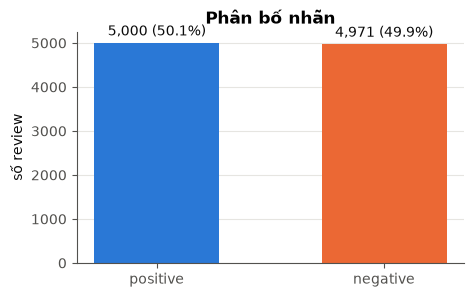

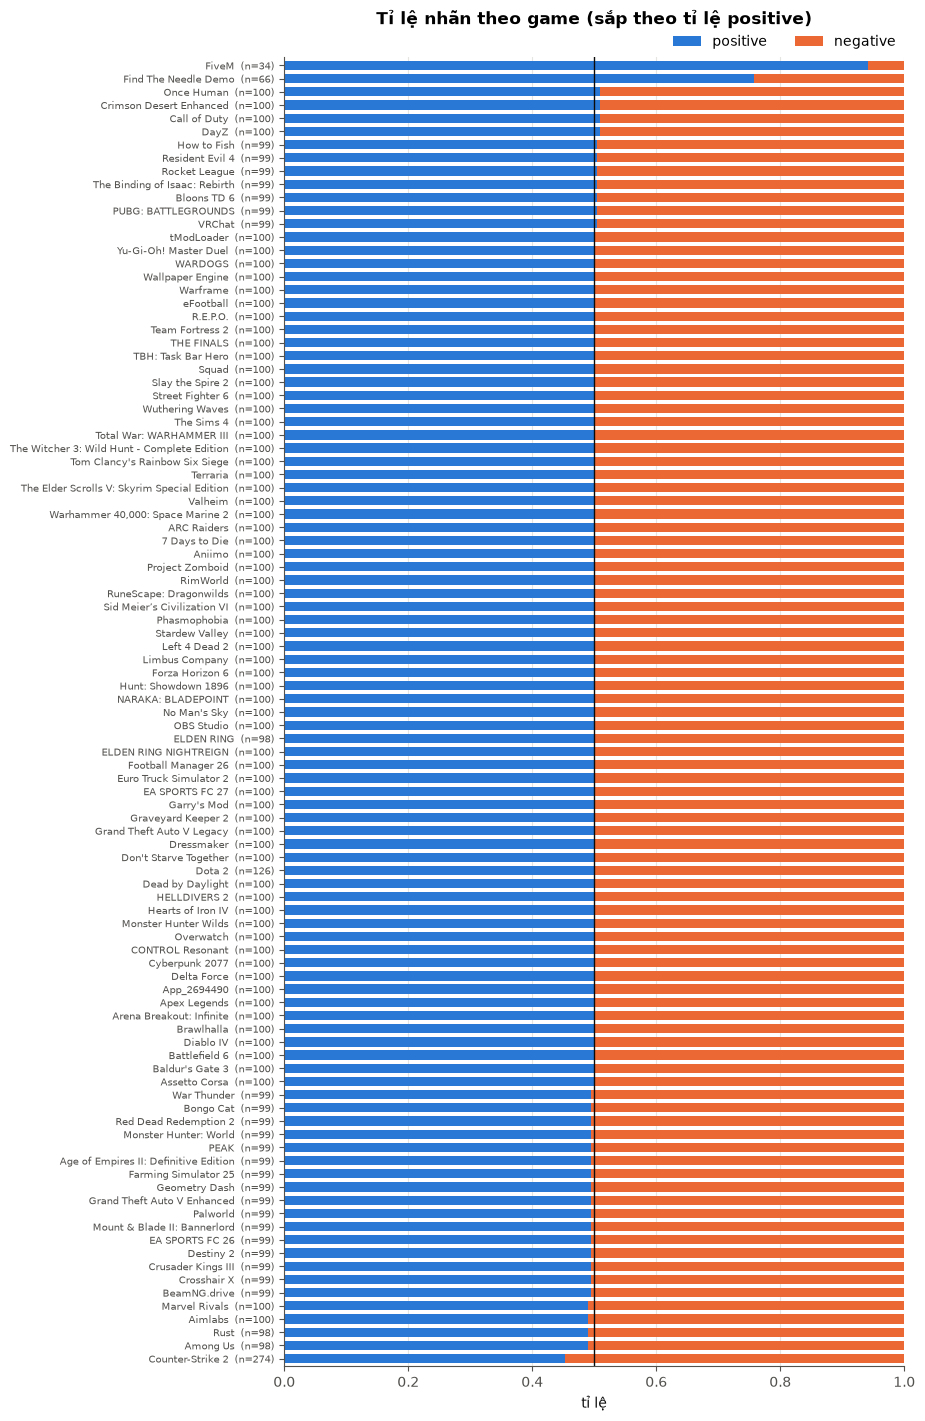

In [17]:
fig, ax = plt.subplots(figsize=(5, 3))
vc = d.sentiment.value_counts().reindex(["positive", "negative"])
bars = ax.bar(vc.index, vc.values, color=[C_POS, C_NEG], width=0.55)
ax.bar_label(bars, labels=[f"{v:,} ({v / len(d):.1%})" for v in vc.values], color=INK, padding=3)
ax.set_title("Phân bố nhãn"); ax.set_ylabel("số review"); ax.grid(axis="x", visible=False)
plt.show()

g = d.groupby("game_name").agg(n=("label", "size"), pos=("label", "mean")).sort_values("pos")
fig, ax = plt.subplots(figsize=(8, 17))
yy = np.arange(len(g))
ax.barh(yy, g.pos, color=C_POS, height=0.7, label="positive")
ax.barh(yy, 1 - g.pos, left=g.pos, color=C_NEG, height=0.7, label="negative")
ax.axvline(0.5, color=INK, lw=1)
ax.set_yticks(yy, [f"{n}  (n={c})" for n, c in zip(g.index, g.n)], fontsize=7)
ax.set_xlim(0, 1); ax.set_ylim(-0.6, len(g) - 0.4); ax.set_xlabel("tỉ lệ"); ax.grid(axis="y", visible=False)
ax.set_title("Tỉ lệ nhãn theo game (sắp theo tỉ lệ positive)", pad=24)
ax.legend(loc="lower right", frameon=False, ncol=2, bbox_to_anchor=(1, 1.0), borderaxespad=0.2)
plt.show()

97/99 game có tỉ lệ positive trong khoảng 45–55% (66 game đúng 50%). Hai game lệch rõ là FiveM (94% positive, n=34)
và Find The Needle Demo (76%, n=66), cũng là hai game có ít review nhất. Counter-Strike 2 có nhiều review nhất (274, 45% positive).

### 4.2 Phân bố playtime (thang log) theo nhãn

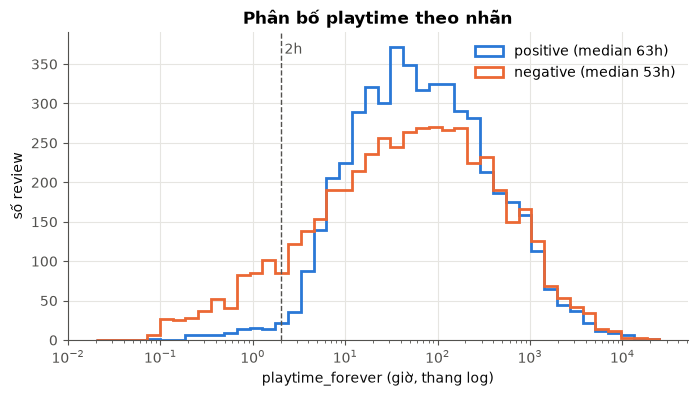

In [18]:
bins = np.logspace(np.log10(d.playtime_forever_hours.min()), np.log10(d.playtime_forever_hours.max()), 45)
fig, ax = plt.subplots(figsize=(8, 4))
for m, c, lab in [(POS, C_POS, "positive"), (NEG, C_NEG, "negative")]:
    x = d.loc[m, "playtime_forever_hours"]
    ax.hist(x, bins=bins, histtype="step", lw=2, color=c, label=f"{lab} (median {x.median():.0f}h)")
ax.set_xscale("log"); ax.set_xlabel("playtime_forever (giờ, thang log)"); ax.set_ylabel("số review")
ax.axvline(PLAYTIME_LOW_H, color=INK2, ls="--", lw=1); ax.text(PLAYTIME_LOW_H * 1.1, ax.get_ylim()[1] * 0.93, "2h", color=INK2)
ax.set_title("Phân bố playtime theo nhãn"); ax.legend(frameon=False)
plt.show()

Hai phân bố gần như chồng nhau từ ~100h trở lên. Khác biệt nằm ở đuôi trái: dưới ~5h, số review negative nhiều hơn hẳn positive.

### 4.3 Tỉ lệ positive theo khoảng playtime

,n,k,pos_rate,ci_lo,ci_hi
playtime_forever_hours,,,,,
<2h,607,82,0.135,0.110,0.165
2–10h,1308,587,0.449,0.422,0.476
10–50h,2763,1567,0.567,0.549,0.586
50–200h,2569,1408,0.548,0.529,0.567
200–1000h,2007,1016,0.506,0.484,0.528
≥1000h,717,340,0.474,0.438,0.511


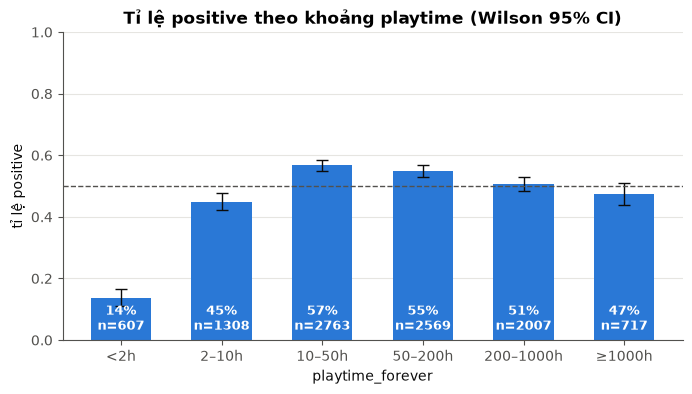

In [19]:
PT_BINS = [0, 2, 10, 50, 200, 1000, np.inf]
PT_LABELS = ["<2h", "2–10h", "10–50h", "50–200h", "200–1000h", "≥1000h"]
pb = d.groupby(pd.cut(d.playtime_forever_hours, PT_BINS, labels=PT_LABELS, right=False), observed=False).label.agg(n="size", k="sum")
pb["pos_rate"] = pb.k / pb.n
pb[["ci_lo", "ci_hi"]] = [wilson(k, n) for k, n in zip(pb.k, pb.n)]
display(pb.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(pb))
ax.bar(x, pb.pos_rate, color=C_POS, width=0.6)
ax.errorbar(x, pb.pos_rate, yerr=[pb.pos_rate - pb.ci_lo, pb.ci_hi - pb.pos_rate], fmt="none", ecolor=INK, capsize=4, lw=1)
for xi, (r, n) in enumerate(zip(pb.pos_rate, pb.n)):
    ax.text(xi, 0.02, f"{r:.0%}\nn={n}", ha="center", va="bottom", color="white", fontsize=9, fontweight="bold")
ax.axhline(d.label.mean(), color=INK2, ls="--", lw=1)
ax.set_xticks(x, PT_LABELS); ax.set_ylim(0, 1); ax.set_ylabel("tỉ lệ positive"); ax.set_xlabel("playtime_forever")
ax.set_title("Tỉ lệ positive theo khoảng playtime (Wilson 95% CI)"); ax.grid(axis="x", visible=False)
plt.show()

Quan hệ **không tuyến tính, dạng chữ ∩**: <2h chỉ 14% positive, tăng lên đỉnh 57% ở 10–50h, rồi giảm dần về 47% ở ≥1000h.
Vì vậy Pearson sẽ đánh giá thấp quan hệ này (xem mục 5).

### 4.4 Độ dài review theo nhãn

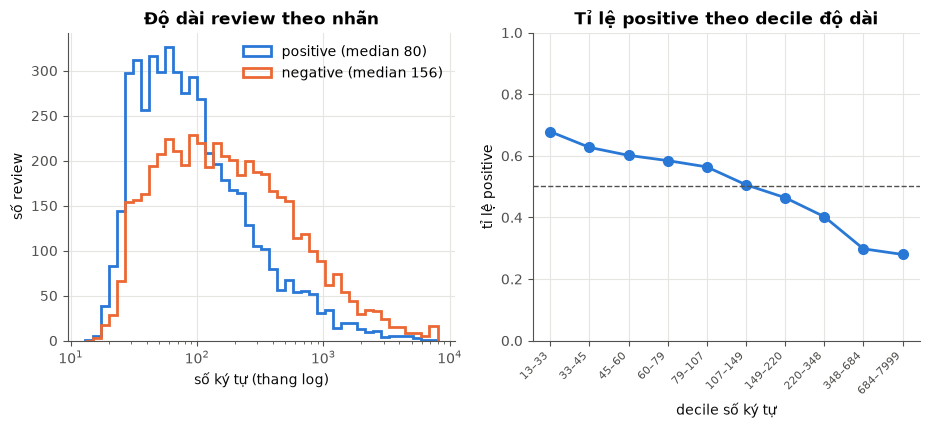

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
lb = np.logspace(np.log10(d.char_len.min()), np.log10(d.char_len.max()), 45)
for m, c, lab in [(POS, C_POS, "positive"), (NEG, C_NEG, "negative")]:
    x = d.loc[m, "char_len"]
    axes[0].hist(x, bins=lb, histtype="step", lw=2, color=c, label=f"{lab} (median {x.median():.0f})")
axes[0].set_xscale("log"); axes[0].set_xlabel("số ký tự (thang log)"); axes[0].set_ylabel("số review")
axes[0].set_title("Độ dài review theo nhãn"); axes[0].legend(frameon=False)
lbr = d.groupby(pd.qcut(d.char_len, 10), observed=True).label.agg(n="size", pos_rate="mean")
axes[1].plot(range(len(lbr)), lbr.pos_rate, marker="o", ms=7, lw=2, color=C_POS)
axes[1].set_xticks(range(len(lbr)), [f"{math.ceil(i.left)}–{int(i.right)}" for i in lbr.index], rotation=45, ha="right", fontsize=8)
axes[1].axhline(d.label.mean(), color=INK2, ls="--", lw=1)
axes[1].set_ylim(0, 1); axes[1].set_ylabel("tỉ lệ positive"); axes[1].set_xlabel("decile số ký tự")
axes[1].set_title("Tỉ lệ positive theo decile độ dài")
plt.show()

Review negative dài hơn: median 156 ký tự so với 80 ở positive. Tỉ lệ positive giảm gần như đơn điệu theo độ dài,
từ 68% (≤ 33 ký tự) xuống 28% (> 684 ký tự).

### 4.5 Tỉ lệ có votes_helpful > 0 theo nhãn (chỉ mô tả)

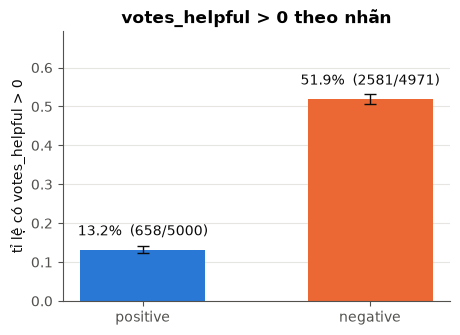

In [21]:
hv = d.groupby("sentiment").flag_has_helpful.agg(n="size", k="sum").reindex(["positive", "negative"])
hv["rate"] = hv.k / hv.n
hv[["ci_lo", "ci_hi"]] = [wilson(k, n) for k, n in zip(hv.k, hv.n)]
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(hv.index, hv.rate, color=[C_POS, C_NEG], width=0.55)
ax.errorbar(range(2), hv.rate, yerr=[hv.rate - hv.ci_lo, hv.ci_hi - hv.rate], fmt="none", ecolor=INK, capsize=4, lw=1)
ax.bar_label(bars, labels=[f"{r:.1%}  ({k}/{n})" for r, k, n in zip(hv.rate, hv.k, hv.n)], padding=8, color=INK)
ax.set_ylim(0, max(hv.ci_hi) * 1.3); ax.set_ylabel("tỉ lệ có votes_helpful > 0")
ax.set_title("votes_helpful > 0 theo nhãn"); ax.grid(axis="x", visible=False)
plt.show()

52% review negative có ít nhất 1 vote helpful, so với 13% ở positive.

### 4.6 Từ khóa nổi bật: positive vs negative (TF-IDF)
TF-IDF trung bình của từng từ trong mỗi lớp, xếp theo hiệu positive − negative (bỏ stopword tiếng Anh, từ xuất hiện ≥ 5 review).

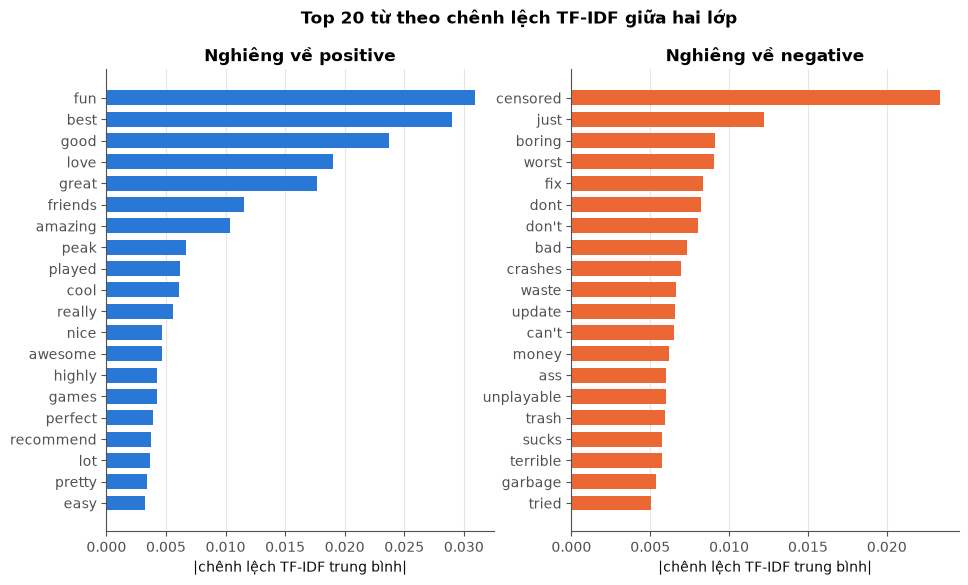

In [22]:
tfv = TfidfVectorizer(stop_words="english", min_df=5, max_df=0.5, sublinear_tf=True,
                      token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b")
X = tfv.fit_transform(d.text_clean)
kw = pd.DataFrame({"term": tfv.get_feature_names_out(),
                   "tfidf_pos": np.asarray(X[POS.values].mean(axis=0)).ravel(),
                   "tfidf_neg": np.asarray(X[NEG.values].mean(axis=0)).ravel()})
kw["diff"] = kw.tfidf_pos - kw.tfidf_neg
top_pos, top_neg = kw.nlargest(20, "diff"), kw.nsmallest(20, "diff")

fig, axes = plt.subplots(1, 2, figsize=(11, 6))
for ax, t, c, title in [(axes[0], top_pos, C_POS, "Nghiêng về positive"), (axes[1], top_neg, C_NEG, "Nghiêng về negative")]:
    t = t.iloc[::-1]
    ax.barh(t.term, t["diff"].abs(), color=c, height=0.7)
    ax.set_title(title); ax.set_xlabel("|chênh lệch TF-IDF trung bình|"); ax.grid(axis="y", visible=False)
fig.suptitle("Top 20 từ theo chênh lệch TF-IDF giữa hai lớp", fontweight="bold")
plt.show()

- Positive: từ khen chung chung (fun, best, good, love, great, amazing) và "friends" (chơi cùng bạn bè).
- Negative: `censored` (từ tục bị Steam che) đứng đầu; tiếp theo là từ chê (boring, worst, bad, trash, garbage)
  và từ về vấn đề kỹ thuật / cập nhật / tiền (fix, crashes, update, unplayable, money, waste).

### 4.7 Phân bố timestamp theo tháng, theo nhãn (chỉ mô tả)

month,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
sentiment,,,,,,,,,,
positive,2.0,19.00,1.0,3.00,1.00,1.00,0.0,1.00,30.00,4942.00
negative,0.0,1.00,1.0,5.00,7.00,10.00,11.0,28.00,420.00,4488.00
pos_rate,1.0,0.95,0.5,0.38,0.12,0.09,0.0,0.03,0.07,0.52


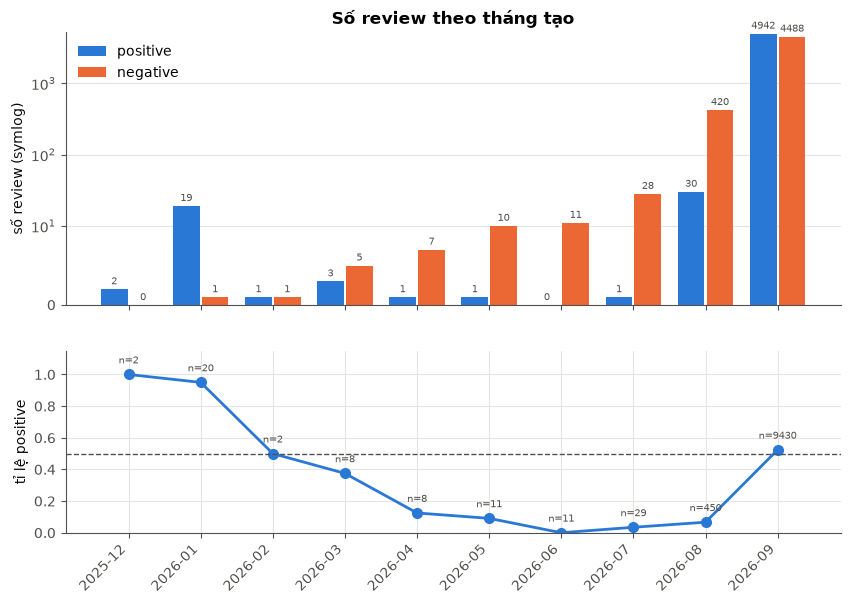

In [23]:
mt = d.groupby(["month", "sentiment"]).size().unstack(fill_value=0).reindex(columns=["positive", "negative"])
mt["pos_rate"] = mt.positive / mt[["positive", "negative"]].sum(axis=1)
display(mt.T.round(2))

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
x = np.arange(len(mt)); w = 0.4
for off, col, c in [(-w / 2, "positive", C_POS), (w / 2, "negative", C_NEG)]:
    b = axes[0].bar(x + off, mt[col], width=w - 0.03, color=c, label=col)
    axes[0].bar_label(b, fontsize=7, color=INK2, padding=2)
axes[0].set_yscale("symlog", linthresh=10); axes[0].set_ylabel("số review (symlog)")
axes[0].set_title("Số review theo tháng tạo"); axes[0].legend(frameon=False); axes[0].grid(axis="x", visible=False)
n_m = mt[["positive", "negative"]].sum(axis=1)
axes[1].plot(x, mt.pos_rate, marker="o", ms=7, lw=2, color=C_POS)
for xi, (r, n) in enumerate(zip(mt.pos_rate, n_m)):
    axes[1].annotate(f"n={n}", (xi, r), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=7, color=INK2)
axes[1].axhline(0.5, color=INK2, ls="--", lw=1); axes[1].set_ylim(0, 1.15); axes[1].set_ylabel("tỉ lệ positive")
axes[1].set_xticks(x, mt.index, rotation=45, ha="right")
plt.show()

94,6% review nằm trong tháng 09/2026 (52% positive). 541 review trước tháng 9 chỉ có 11% positive:
tháng tạo review gắn chặt với nhãn → xác nhận không nên dùng timestamp làm feature.

## 5. Tương quan feature – nhãn
- Pearson (với nhãn nhị phân = point-biserial) chỉ đo quan hệ tuyến tính → kèm Spearman (đơn điệu),
  mutual information (bắt cả quan hệ không đơn điệu) và tỉ lệ positive theo decile.
- MI tính bằng nats; trần với nhãn nhị phân cân bằng là ln 2 ≈ 0,693. MI biến liên tục dùng ước lượng kNN (k=3, seed 0).

In [24]:
y = d.label.values

def assoc_row(col, group):
    x = d[col].astype(float).values
    return {"feature": col, "nhóm": group,
            "pearson_r": stats.pearsonr(x, y)[0], "spearman_rho": stats.spearmanr(x, y)[0],
            "MI_nats": mutual_info_classif(x.reshape(-1, 1), y, discrete_features=d[col].nunique() <= 2,
                                           n_neighbors=3, random_state=RNG)[0]}

rows = [assoc_row(c, "feature cho model") for c in MODEL_FEATURES]
rows += [assoc_row(c, "chỉ mô tả") for c in ["flag_has_helpful", "log_votes_helpful", "timestamp_created"]]
rows += [assoc_row(c, "đặc điểm text") for c in ["has_censored", "n_emoji", "unique_word_ratio"]]
codes = d.game_name.astype("category").cat.codes.values.reshape(-1, 1)
chi2 = stats.chi2_contingency(pd.crosstab(d.game_name, d.label))[0]
rows.append({"feature": "game_name", "nhóm": "phân loại",
             "MI_nats": mutual_info_classif(codes, y, discrete_features=True, random_state=RNG)[0],
             "cramers_v": math.sqrt(chi2 / len(d))})
assoc = pd.DataFrame(rows).sort_values("MI_nats", ascending=False)
display(assoc.round(3).reset_index(drop=True))

,feature,nhóm,pearson_r,spearman_rho,MI_nats,cramers_v
0,timestamp_created,chỉ mô tả,0.169,0.361,0.108,NaN
1,log_votes_helpful,chỉ mô tả,-0.392,-0.429,0.107,NaN
2,flag_has_helpful,chỉ mô tả,-0.414,-0.414,0.090,NaN
3,char_len,feature cho model,-0.165,-0.257,0.044,NaN
4,word_count,feature cho model,-0.165,-0.244,0.037,NaN
5,unique_word_ratio,đặc điểm text,0.203,0.193,0.034,NaN
6,log_playtime,feature cho model,0.089,0.077,0.022,NaN
7,flag_playtime_lt2h,feature cho model,-0.187,-0.187,0.019,NaN
8,has_censored,đặc điểm text,-0.189,-0.189,0.019,NaN
9,n_emoji,đặc điểm text,-0.001,0.026,0.014,NaN


In [25]:
bin_tables = {}
for col in ["log_playtime", "char_len", "word_count"]:
    q = pd.qcut(d[col], 10)
    bin_tables[col] = d.groupby(q, observed=True).label.mean().values
dec = pd.DataFrame(bin_tables, index=[f"D{i}" for i in range(1, 11)]).T
print("Tỉ lệ positive theo decile (D1 = thấp nhất):")
display(dec.round(2))

flag_tbl = pd.DataFrame([{"cờ": c, "số dòng": int(d[c].sum()),
                          "pos_rate khi cờ=1": d.loc[d[c], "label"].mean() if d[c].any() else np.nan,
                          "pos_rate khi cờ=0": d.loc[~d[c], "label"].mean()}
                         for c in ["flag_playtime_lt2h", "flag_has_helpful", "has_censored"] + FLAG_COLS + ["flag_lang_uncertain"]])
display(flag_tbl.round(3))

Tỉ lệ positive theo decile (D1 = thấp nhất):


,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
log_playtime,0.20,0.51,0.56,0.56,0.59,0.55,0.55,0.52,0.51,0.47
char_len,0.68,0.63,0.60,0.58,0.56,0.51,0.46,0.40,0.30,0.28
word_count,0.64,0.64,0.62,0.57,0.56,0.53,0.46,0.39,0.31,0.28


,cờ,số dòng,pos_rate khi cờ=1,pos_rate khi cờ=0
0,flag_playtime_lt2h,607,0.135,0.525
1,flag_has_helpful,3239,0.203,0.645
2,has_censored,822,0.186,0.530
3,flag_non_english,0,NaN,0.501
4,flag_mixed_language,2,0.000,0.502
5,flag_truncated,8,0.125,0.502
6,flag_spam_repeat,10,0.200,0.502
7,flag_too_short,1,1.000,0.501
8,flag_lang_uncertain,424,0.675,0.494


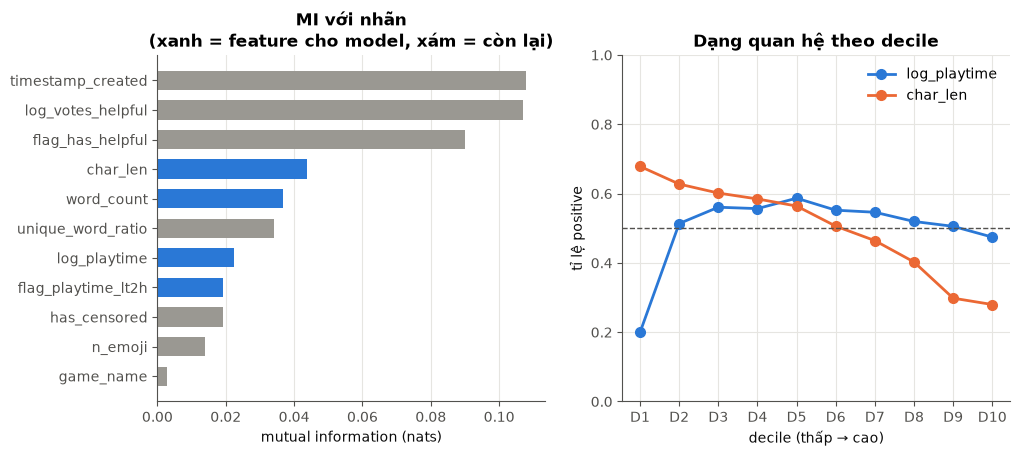

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
a = assoc.sort_values("MI_nats")
axes[0].barh(a.feature, a.MI_nats, color=[C_POS if g == "feature cho model" else "#9a9892" for g in a["nhóm"]], height=0.65)
axes[0].set_xlabel("mutual information (nats)"); axes[0].set_title("MI với nhãn\n(xanh = feature cho model, xám = còn lại)")
axes[0].grid(axis="y", visible=False)
for col, c in [("log_playtime", C_POS), ("char_len", C_NEG)]:
    axes[1].plot(range(10), dec.loc[col], marker="o", ms=7, lw=2, label=col, color=c)
axes[1].axhline(d.label.mean(), color=INK2, ls="--", lw=1)
axes[1].set_xticks(range(10), dec.columns); axes[1].set_ylim(0, 1)
axes[1].set_xlabel("decile (thấp → cao)"); axes[1].set_ylabel("tỉ lệ positive")
axes[1].set_title("Dạng quan hệ theo decile"); axes[1].legend(frameon=False)
plt.show()

**Nhận xét tương quan**
- Trong nhóm feature cho model, **độ dài** liên quan mạnh nhất: `char_len` MI ≈ 0,044, Spearman ≈ −0,26, giảm gần đơn điệu.
- **Playtime**: Pearson chỉ ≈ 0,09 vì quan hệ dạng chữ ∩ (D1 20% → đỉnh ~59% ở D5 → 47% ở D10). MI ≈ 0,022 và bảng decile
  cho thấy quan hệ rõ hơn Pearson. Phần lớn tín hiệu nằm ở nhóm < 2h (14% positive so với 52% ở nhóm còn lại).
- Các cột chỉ mô tả có MI cao hơn mọi feature cho model: `timestamp_created` ≈ 0,108, `log_votes_helpful` ≈ 0,107.
  Đây đúng là hai cột đã loại khỏi feature.
- `has_censored`: 19% positive khi có từ tục bị che, so với 53% khi không có.
- `game_name` gần như không liên quan đến nhãn (MI ≈ 0,003, Cramér's V ≈ 0,07), khớp với việc dữ liệu cân bằng theo game.

## 6. Quan hệ giữa các feature — định hướng cho model
Thêm vài đặc trưng text đơn giản chỉ để khám phá (chưa chốt làm feature):
- `exclaim_rate`, `has_question`: số dấu `!` trên 100 ký tự, có dấu `?` hay không
- `upper_ratio`: tỉ lệ chữ in hoa trên tổng chữ cái
- `has_score`: có điểm dạng `x/10` (vd "10/10", "2/10") và `score_x10` là điểm đó
- `has_checkbox`: review dùng template checkbox ☐ ☑

In [27]:
SCORE_RE = re.compile(r"(?<![\d/])(\d{1,2}(?:\.\d)?)\s*/\s*10\b")

def first_score(s):
    m = SCORE_RE.search(s)
    return float(m.group(1)) if m and float(m.group(1)) <= 10 else np.nan

letters = d.text_clean.str.count(r"[A-Za-z]").clip(lower=1)
d["exclaim_rate"] = d.text_clean.str.count("!") / d.char_len * 100
d["has_question"] = d.text_clean.str.contains("?", regex=False)
d["upper_ratio"] = d.text_clean.str.count(r"[A-Z]") / letters
d["score_x10"] = d.text_clean.map(first_score)
d["has_score"] = d.score_x10.notna()
d["has_checkbox"] = d.text_clean.str.contains("[☐☑☒▢]")
d["has_emoji"] = d.n_emoji > 0

EXPLORE = ["exclaim_rate", "has_question", "upper_ratio", "has_score", "has_checkbox", "has_emoji", "has_censored", "unique_word_ratio"]
display(pd.DataFrame([{"đặc trưng": c,
                       "tỉ lệ / TB": d[c].mean(),
                       "pos_rate khi có / top 50%": d.loc[d[c] > (0 if d[c].dtype == bool else d[c].median()), "label"].mean(),
                       "spearman với nhãn": stats.spearmanr(d[c].astype(float), d.label)[0]} for c in EXPLORE]).round(3))

,đặc trưng,tỉ lệ / TB,pos_rate khi có / top 50%,spearman với nhãn
0,exclaim_rate,0.173,0.603,0.071
1,has_question,0.073,0.260,-0.136
2,upper_ratio,0.050,0.504,-0.007
3,has_score,0.044,0.742,0.104
4,has_checkbox,0.001,0.375,-0.007
5,has_emoji,0.008,0.643,0.026
6,has_censored,0.082,0.186,-0.189
7,unique_word_ratio,0.872,0.577,0.193


In [28]:
# Điểm tự chấm x/10 so với nhãn
sc = d[d.has_score]
print(f"Review có điểm x/10: {len(sc)} ({len(sc) / len(d):.1%})")
sc_tbl = sc.groupby(pd.cut(sc.score_x10, [-0.1, 3, 5, 6, 7, 8, 10], labels=["0–3", "3–5", "5–6", "6–7", "7–8", "8–10"]),
                    observed=False).label.agg(n="size", pos_rate="mean")
display(sc_tbl.round(3).T)

Review có điểm x/10: 442 (4.4%)


score_x10,0–3,3–5,5–6,6–7,7–8,8–10
n,48.000,15.000,10.0,16.000,35.000,318.000
pos_rate,0.042,0.267,0.2,0.438,0.914,0.884


- `has_score` (4,4% review) phân tách rất rõ: điểm ≥ 7/10 → ~89% positive, ≤ 3/10 → 4%. Vùng 5–7 lẫn lộn.
- `has_question` và `has_censored` đi cùng negative; `upper_ratio`, `has_checkbox`, `has_emoji` gần như không liên quan.

### 6.1 Heatmap tương quan giữa các feature (Spearman)
Spearman thay cho Pearson vì playtime, độ dài, votes đều lệch mạnh. Hàng/cột `label` ở trên cùng để đối chiếu.
Cột chỉ mô tả (`log_votes_helpful`, `timestamp_created`) vẫn đưa vào để xem chúng đi cùng feature nào.

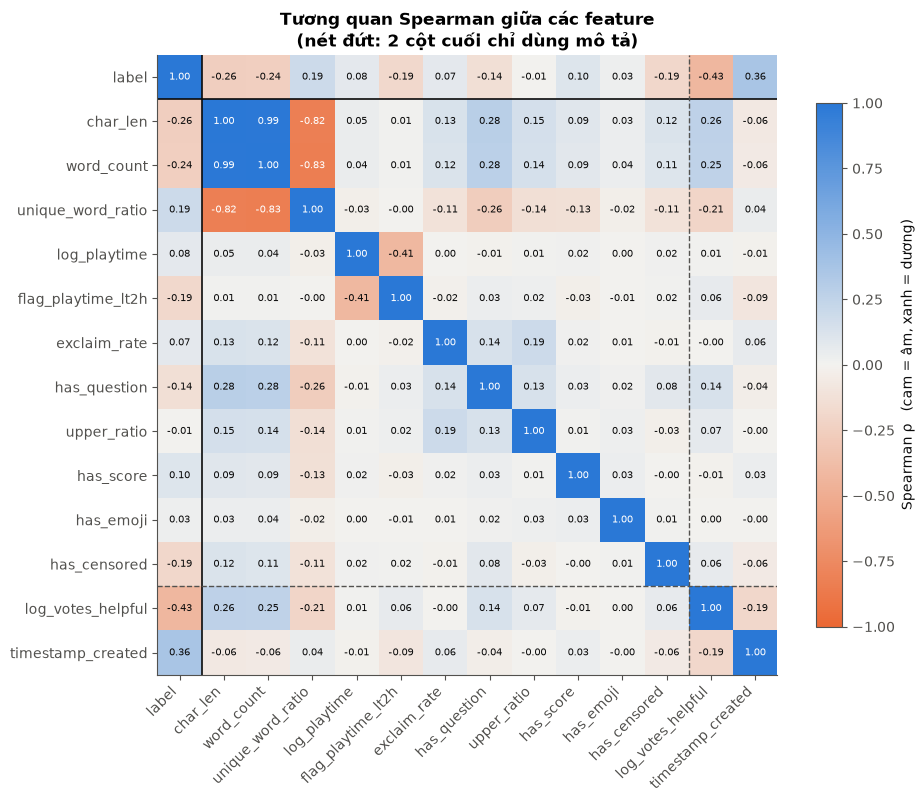

In [29]:
from matplotlib.colors import LinearSegmentedColormap
DIV = LinearSegmentedColormap.from_list("div", [C_NEG, "#f3f2ef", C_POS])

HEAT = ["label", "char_len", "word_count", "unique_word_ratio", "log_playtime", "flag_playtime_lt2h",
        "exclaim_rate", "has_question", "upper_ratio", "has_score", "has_emoji", "has_censored",
        "log_votes_helpful", "timestamp_created"]
corr = d[HEAT].astype(float).corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(HEAT)), HEAT, rotation=45, ha="right"); ax.set_yticks(range(len(HEAT)), HEAT)
ax.grid(False)
for i in range(len(HEAT)):
    for j in range(len(HEAT)):
        v = corr.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="white" if abs(v) > 0.6 else INK)
ax.axhline(0.5, color=INK, lw=1.2); ax.axvline(0.5, color=INK, lw=1.2)
ax.axhline(len(HEAT) - 2.5, color=INK2, lw=1, ls="--"); ax.axvline(len(HEAT) - 2.5, color=INK2, lw=1, ls="--")
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman ρ   (cam = âm, xanh = dương)")
ax.set_title("Tương quan Spearman giữa các feature\n(nét đứt: 2 cột cuối chỉ dùng mô tả)")
plt.show()

- **Cụm độ dài**: `char_len` – `word_count` ρ = 0,99 (trùng nhau), `unique_word_ratio` ρ ≈ −0,82 với độ dài (review dài lặp từ nhiều hơn).
  `has_question` cũng đi cùng độ dài (ρ = 0,28).
- **Playtime gần như độc lập với mọi feature text** (|ρ| ≤ 0,05) → mang thông tin khác với nhóm độ dài.
- Với nhãn: mạnh nhất trong nhóm dùng được là `char_len` (−0,26), `unique_word_ratio` (0,19), `flag_playtime_lt2h` (−0,19),
  `has_censored` (−0,19). Hai cột chỉ mô tả còn mạnh hơn: `log_votes_helpful` (−0,43), `timestamp_created` (0,36).
- `log_votes_helpful` đi cùng độ dài (0,26) và có câu hỏi (0,14): review dài nhận nhiều vote helpful hơn.

### 6.2 Tương tác playtime × độ dài
Nếu hai tín hiệu độc lập, tỉ lệ positive sẽ thay đổi theo cả hai chiều. Ô ghi tỉ lệ positive và số review.

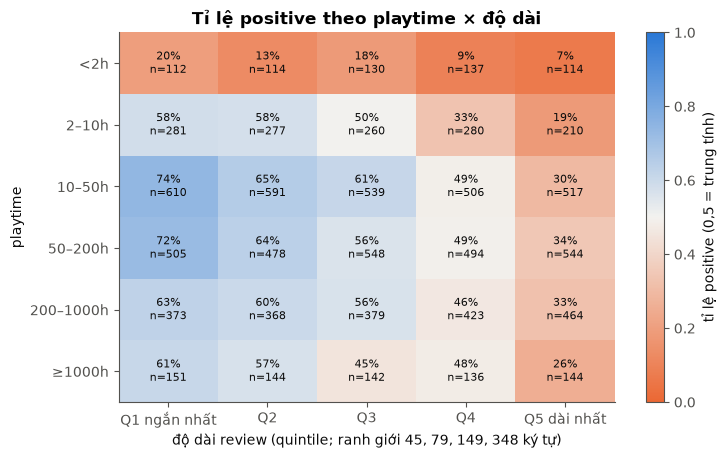

In [30]:
d["pt_bin"] = pd.cut(d.playtime_forever_hours, PT_BINS, labels=PT_LABELS, right=False)
d["len_q"] = pd.qcut(d.char_len, 5, labels=["Q1 ngắn nhất", "Q2", "Q3", "Q4", "Q5 dài nhất"])
piv = d.pivot_table(index="pt_bin", columns="len_q", values="label", aggfunc="mean", observed=False)
cnt = d.pivot_table(index="pt_bin", columns="len_q", values="label", aggfunc="size", observed=False)

fig, ax = plt.subplots(figsize=(8, 4.8))
im = ax.imshow(piv, cmap=DIV, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(piv.shape[1]), piv.columns); ax.set_yticks(range(piv.shape[0]), piv.index); ax.grid(False)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        ax.text(j, i, f"{piv.iat[i, j]:.0%}\nn={cnt.iat[i, j]}", ha="center", va="center", fontsize=8, color=INK)
fig.colorbar(im, ax=ax, label="tỉ lệ positive (0,5 = trung tính)")
ax.set_xlabel(f"độ dài review (quintile; ranh giới {', '.join(str(int(v)) for v in d.char_len.quantile([.2, .4, .6, .8]))} ký tự)")
ax.set_ylabel("playtime")
ax.set_title("Tỉ lệ positive theo playtime × độ dài")
plt.show()

Hai tín hiệu **cộng dồn**: trong mỗi khoảng playtime, tỉ lệ positive giảm dần theo độ dài; trong mỗi quintile độ dài,
nhóm < 2h luôn thấp nhất. Hai góc đối lập: 74% (10–50h, ngắn nhất) và 7% (< 2h, dài nhất).

### 6.3 Quan hệ có ổn định giữa các game không?
Tính Spearman(feature, nhãn) **riêng trong từng game** (97 game có ≥ 90 review). Nếu phân bố hẹp và cùng dấu,
quan hệ ổn định giữa các game; nếu rộng, quan hệ phụ thuộc game.

,count,mean,10%,50%,90%,tỉ lệ game cùng dấu với toàn cục
char_len,97.0,-0.270,-0.422,-0.274,-0.099,0.990
log_playtime,97.0,0.103,-0.158,0.090,0.383,0.711
has_censored,96.0,-0.184,-0.290,-0.198,-0.063,0.938
exclaim_rate,97.0,0.068,-0.052,0.067,0.209,0.722
upper_ratio,97.0,-0.005,-0.148,-0.017,0.154,0.546


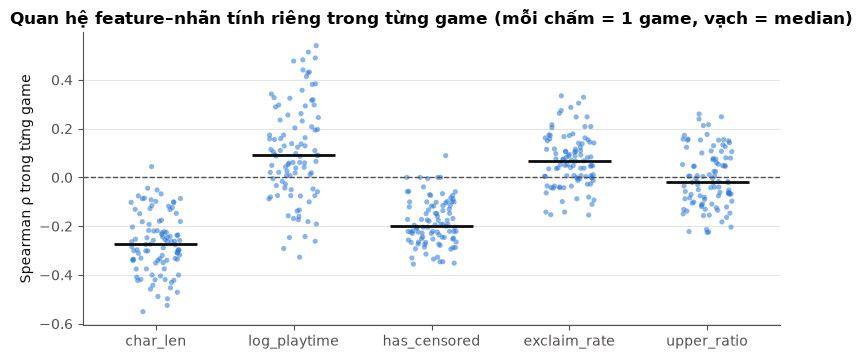

In [31]:
import warnings
warnings.filterwarnings("ignore", category=stats.ConstantInputWarning)   # game không có review nào dính has_censored
big = d.groupby("game_name").filter(lambda g: len(g) >= 90)
per_game_rho = pd.DataFrame({c: big.groupby("game_name").apply(lambda g: stats.spearmanr(g[c].astype(float), g.label)[0],
                                                                  include_groups=False)
                             for c in ["char_len", "log_playtime", "has_censored", "exclaim_rate", "upper_ratio"]})
summary_rho = per_game_rho.describe(percentiles=[.1, .5, .9]).T[["count", "mean", "10%", "50%", "90%"]]
summary_rho["tỉ lệ game cùng dấu với toàn cục"] = [(np.sign(per_game_rho[c]) == np.sign(stats.spearmanr(d[c].astype(float), d.label)[0])).mean()
                                                   for c in per_game_rho.columns]
display(summary_rho.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
for i, c in enumerate(per_game_rho.columns):
    v = per_game_rho[c].dropna()
    jitter = np.random.default_rng(RNG).uniform(-0.18, 0.18, len(v))
    ax.scatter(np.full(len(v), i) + jitter, v, s=14, color=C_POS, alpha=0.55, edgecolor="none")
    ax.hlines(v.median(), i - 0.3, i + 0.3, color=INK, lw=2)
ax.axhline(0, color=INK2, lw=1, ls="--")
ax.set_xticks(range(per_game_rho.shape[1]), per_game_rho.columns); ax.set_ylabel("Spearman ρ trong từng game")
ax.set_title("Quan hệ feature–nhãn tính riêng trong từng game (mỗi chấm = 1 game, vạch = median)")
ax.grid(axis="x", visible=False)
plt.show()

In [32]:
# Game có quan hệ độ dài–nhãn yếu nhất / ngược xu hướng chung
display(per_game_rho.sort_values("char_len", ascending=False).head(5).round(3))

,char_len,log_playtime,has_censored,exclaim_rate,upper_ratio
game_name,,,,,
Tom Clancy's Rainbow Six Siege,0.044,-0.247,0.089,0.050,0.003
NARAKA: BLADEPOINT,-0.044,-0.027,-0.101,0.274,0.239
ELDEN RING NIGHTREIGN,-0.052,0.203,-0.067,0.041,0.216
Apex Legends,-0.068,-0.160,-0.149,0.103,-0.004
tModLoader,-0.076,0.088,-0.352,0.204,-0.084


In [33]:
# Playtime tương đối trong game (percentile) so với playtime tuyệt đối
d["playtime_pct_in_game"] = d.groupby("game_name").playtime_forever_hours.rank(pct=True)
display(d.groupby("game_name").playtime_forever_hours.median().describe(percentiles=[.1, .5, .9]).round(1).to_frame("median playtime / game").T)
cmp = pd.DataFrame([{"feature": c,
                     "MI_nats": mutual_info_classif(d[[c]].astype(float), d.label, n_neighbors=3, random_state=RNG)[0],
                     "spearman": stats.spearmanr(d[c], d.label)[0]} for c in ["log_playtime", "playtime_pct_in_game"]])
display(cmp.round(4))
pct_bins = d.groupby(pd.qcut(d.playtime_pct_in_game, 10, labels=[f"D{i}" for i in range(1, 11)]), observed=True).label.mean()
display(pct_bins.round(2).to_frame("pos_rate theo decile playtime_pct_in_game").T)

,count,mean,std,min,10%,50%,90%,max
median playtime / game,99.0,105.6,156.4,4.0,17.4,70.6,199.1,1291.2


,feature,MI_nats,spearman
0,log_playtime,0.0223,0.0772
1,playtime_pct_in_game,0.0223,0.0981


playtime_pct_in_game,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
pos_rate theo decile playtime_pct_in_game,0.26,0.47,0.52,0.54,0.57,0.56,0.54,0.53,0.51,0.52


- `char_len`: quan hệ âm ở 96/97 game (median ρ −0,27) → **ổn định, tổng quát được giữa các game**. `has_censored` cùng dấu ở 94%.
- `log_playtime`: chỉ 71% game cùng dấu, ρ từng game trải từ −0,16 đến 0,38 (10–90%) → **phụ thuộc game**.
- Median playtime mỗi game chênh rất lớn (17h ở 10% đến 199h ở 90%). Dù vậy, đổi playtime sang percentile trong game
  không tăng MI (0,022 như cũ): tín hiệu nằm ở giờ chơi tuyệt đối thấp (< 2h), không phải ở vị trí tương đối trong game.

## 7. Insight & định hướng model

### Insight chính (đều là tương quan)

| # | Insight | Số liệu |
|---|---|---|
| 1 | **Nội dung text là tín hiệu chính.** Feature meta mạnh nhất cũng chỉ có MI ≈ 0,044 (trần 0,693), trong khi từ vựng tách hai lớp rất rõ | TF-IDF: fun/best/love vs censored/boring/worst/crashes |
| 2 | **Review càng dài càng nghiêng negative**, ổn định ở hầu hết game | ρ = −0,26 toàn cục; cùng dấu ở 96/97 game (median ρ −0,27) |
| 3 | **Playtime dạng chữ ∩**; tín hiệu tập trung ở nhóm < 2h | < 2h: 14% positive; 10–50h: 57%; ≥ 1000h: 47%. Pearson chỉ 0,09 |
| 4 | **Playtime và độ dài gần như độc lập** (ρ = 0,05) và **cộng dồn**: mỗi hàng của heatmap 6.2 giảm theo độ dài, mỗi cột thấp nhất ở < 2h | từ 74% (10–50h, ngắn nhất) xuống 7% (< 2h, dài nhất) |
| 5 | Quan hệ playtime–nhãn **thay đổi theo game** | cùng dấu ở 71% game; ρ từng game từ −0,16 đến 0,38 (10–90%) |
| 6 | **Điểm tự chấm x/10** rất mạnh nhưng hiếm | 4,4% review; ≥ 7/10 → ~89% positive, ≤ 3/10 → 4% |
| 7 | Từ tục bị che và câu hỏi đi cùng negative | `has_censored` ρ = −0,19 (19% vs 53% positive); `has_question` ρ = −0,14 |
| 8 | **Dư thừa**: `char_len` ≈ `word_count` (ρ = 0,99); `unique_word_ratio` chủ yếu phản ánh độ dài (ρ = −0,82) | — |
| 9 | **Cột không được dùng có tương quan mạnh nhất**: `log_votes_helpful` ρ = −0,43, `timestamp_created` ρ = 0,36; votes còn đi cùng độ dài (ρ = 0,26) | review trước 09/2026: 11% positive |
| 10 | `game_name` gần như không mang thông tin nhãn; `!`, chữ in hoa, emoji rất yếu | MI(game) ≈ 0,003; ρ(upper_ratio) ≈ 0 |

### Định hướng lên kế hoạch model

**Đầu vào**
- Chính: `text_clean` (giữ token `<censored>` và emoji).
- Phụ (meta): 1 biến độ dài (`char_len` **hoặc** `word_count`, không cả hai), playtime dạng **bin/one-hot**
  (hoặc để mô hình cây tự cắt) thay cho `log_playtime` tuyến tính, `has_score` + `score_x10`, `has_question`.
- Loại: `votes_helpful`, `timestamp_created`, `month`, `voted_up`. Không cần `game_name`.

**Thứ tự thử nghiệm đề xuất**
1. Baseline chỉ meta (logistic/GBM) → biết phần tín hiệu ngoài text.
2. TF-IDF (word + char n-gram) + Logistic Regression → baseline text.
3. TF-IDF + meta → xem meta có bổ sung thêm không (insight 4 gợi ý playtime là thông tin độc lập với độ dài).
4. Transformer fine-tune (vd DistilRoBERTa/DeBERTa) trên text; review dài > 512 token cần cắt head+tail.

**Đánh giá**
- Nhãn cân bằng → accuracy / F1 / ROC-AUC đều dùng được; split stratified theo nhãn.
- Thêm **GroupKFold theo game** để đo khả năng tổng quát sang game chưa thấy (insight 5: quan hệ playtime khác nhau giữa các game).
- Báo cáo lỗi theo nhóm: < 2h, review rất dài, review có `<censored>`, 20 dòng dính cờ.

**Việc còn mở**
- Map tên `App_2694490`.
- `playtime_forever` là giờ chơi lúc crawl; nếu crawl lại được `playtime_at_review` thì feature playtime sạch hơn.
- `df` trong notebook (9.971 dòng) là dữ liệu đã làm sạch để dùng cho bước train.

## 8. Lưu dữ liệu sạch cho model
Ghi các cột cần cho `model.ipynb`: text đã làm sạch, nhãn, meta, cờ chất lượng. `votes_helpful` và `timestamp_created` vẫn được ghi vì mô hình chấm mức hữu ích cần (nhãn và biến kiểm soát), nhưng **không** dùng làm feature cho mô hình sentiment.

In [34]:
EXPORT = ["review_id", "app_id", "game_name", "text_clean", "label", "sentiment", "playtime_forever_hours",
          "votes_helpful", "timestamp_created", "char_len", "word_count", "has_censored"] + FLAG_COLS + ["any_flag", "flag_lang_uncertain"]
df[EXPORT].to_csv("data/steam_reviews_clean.csv", index=False, encoding="utf-8")
print("Đã ghi data/steam_reviews_clean.csv", df[EXPORT].shape)

Đã ghi data/steam_reviews_clean.csv (9971, 19)
